<!--

    Gaia Data Processing and Analysis Consortium (DPAC) 
    Co-ordination Unit 9 Work Package 930
    
    (c) 2005-2025 Gaia DPAC
    
    This program is free software: you can redistribute it and/or modify
    it under the terms of the GNU General Public License as published by
    the Free Software Foundation, either version 3 of the License, or
    (at your option) any later version.

    This program is distributed in the hope that it will be useful,
    but WITHOUT ANY WARRANTY; without even the implied warranty of
    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
    GNU General Public License for more details.

    You should have received a copy of the GNU General Public License
    along with this program.  If not, see <https://www.gnu.org/licenses/>.
    -->

# Using ML to define an astrometrically clean sample of stars

Follows the Gaia EDR3 performance verification "The Gaia Catalogue of Nearby Stars" (Smart et al. 2021) in classifying astrometric solutions as good or bad via supervised ML. Employs a Random Forrest classifier plus appropriately defined training sets - see https://arxiv.org/abs/2012.02061 for further details. The work flow implemented here follows closely that described in Section 2, "GCNS Generation" (GCNS = Gaia Catalogue of Nearby Stars) and is designed to clean up a 100pc (= nearby) sample.

   

In [ ]:
import dask.dataframe as dd
import numpy as np
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import math
import os
from pathlib import Path

In [2]:
from dask.distributed import Client
c = Client('tcp://simple-scheduler.dask-operator.svc.cluster.local:8786')

/usr/local/lib/python3.10/site-packages/distributed/client.py:1612: VersionMismatchWarning: Mismatched versions found

+---------+-----------------+-----------------+-----------------+
| Package | Client          | Scheduler       | Workers         |
+---------+-----------------+-----------------+-----------------+
| lz4     | 4.4.4           | 4.3.3           | 4.3.3           |
| numpy   | 2.2.6           | 2.2.2           | 2.2.2           |
| python  | 3.10.16.final.0 | 3.10.12.final.0 | 3.10.12.final.0 |
| toolz   | 1.0.0           | 0.12.0          | 0.12.0          |
| tornado | 6.4.1           | 6.4.2           | 6.4.2           |
+---------+-----------------+-----------------+-----------------+
  warnings.warn(version_module.VersionMismatchWarning(msg[0]["warning"]))


Define astrometric features and filters:

In [ ]:
# this is the set of astrometric features to be used. In reality several iterations of this workflow might be required with an expanded set, and some figure-of-merit,
# e.g. Gini index, would be used to select those most important to the RF classification - cf. Table A.1 in the GCNS paper.
astrometric_features = [
    'parallax_error', 
    'parallax_over_error',
    'astrometric_sigma5d_max',
    'pmra_error',
    'pmdec_error',
    'astrometric_excess_noise',
    'ipd_gof_harmonic_amplitude',
    'ruwe', 
    'visibility_periods_used',
    'pmdec',
    'pmra',
    'ipd_frac_odd_win',
    'ipd_frac_multi_peak',
    'astrometric_gof_al',
    'parallax_pmdec_corr',
    'astrometric_excess_noise_sig'
]
# ... the last two are included to cross check against the Gini index results presented in the paper.

df = dd.read_parquet(Path(os.environ['DASK_DATA_PATH_GAIA_DR3_SSD']).joinpath("GDR3_GAIA_SOURCE"))

# Step 1: Conservative parallax filter: |parallax| > 8.0
raw_sources_df = df[df['parallax'].abs() > 8.0]

# Step 2: Add photometric consistency indicators (same as before)
raw_sources_df['fgbp_grp_0p5'] = 1.15436 + 0.033772 * raw_sources_df['bp_rp'] + 0.032277 * raw_sources_df['bp_rp'] ** 2
raw_sources_df['fgbp_grp_0p5_4p0'] = (
    1.162004 + 0.011464 * raw_sources_df['bp_rp'] +
    0.049255 * raw_sources_df['bp_rp'] ** 2 - 0.005879 * raw_sources_df['bp_rp'] ** 3
)
raw_sources_df['fgbp_grp_4p0'] = 1.057572 + 0.0140537 * raw_sources_df['bp_rp']
raw_sources_df['sig_cstarg'] = 0.0059898 + 8.817481e-12 * raw_sources_df['phot_g_mean_mag'] ** 7.618399

# Step 3: Apply ABS() to parallax_over_error if needed
if 'parallax_over_error' in raw_sources_df.columns:
    raw_sources_df['parallax_over_error'] = raw_sources_df['parallax_over_error'].abs()

# Step 4: Select only the required columns
required_columns = [
    'source_id', 'random_index', 'phot_g_mean_mag', 'phot_bp_rp_excess_factor',
    'bp_rp', 'g_rp', 'parallax', 'ra', 'dec', 'b'
] + astrometric_features + [
    'fgbp_grp_0p5', 'fgbp_grp_0p5_4p0', 'fgbp_grp_4p0', 'sig_cstarg'
]

# Filter to only these columns
raw_sources_df = raw_sources_df[required_columns]

# Step 5: Optionally persist the data (equivalent to Spark's .cache())
raw_sources = raw_sources_df.persist()

# Step 6: Trigger computation and show count (like .count() in Spark)
print("Number of raw sources:", raw_sources.shape[0].compute())



Number of raw sources: 1724028


In [4]:
# plot an observational Hertzsprung-Russell diagram (aka colour / absolute magnitude diagram) for the unclassified sample to show the problem,
# include the photometric consistency filter to show the problem is astrometric in addition to photometric

# Apply parallax filter and quick_plot_filter (sampling)
filtered_df = raw_sources[
    (raw_sources['parallax'] > 8.0) &
    (raw_sources['random_index'] % 25 == 0)
]

# Compute m_g = phot_g_mean_mag + 5 * log10(parallax / 100.0)
unclassified_camd_df = filtered_df.assign(
    m_g = filtered_df['phot_g_mean_mag'] + 5.0 * np.log10(filtered_df['parallax'] / 100.0)
)[['m_g', 'g_rp']]

print(unclassified_camd_df.columns)

Index(['m_g', 'g_rp'], dtype='object')


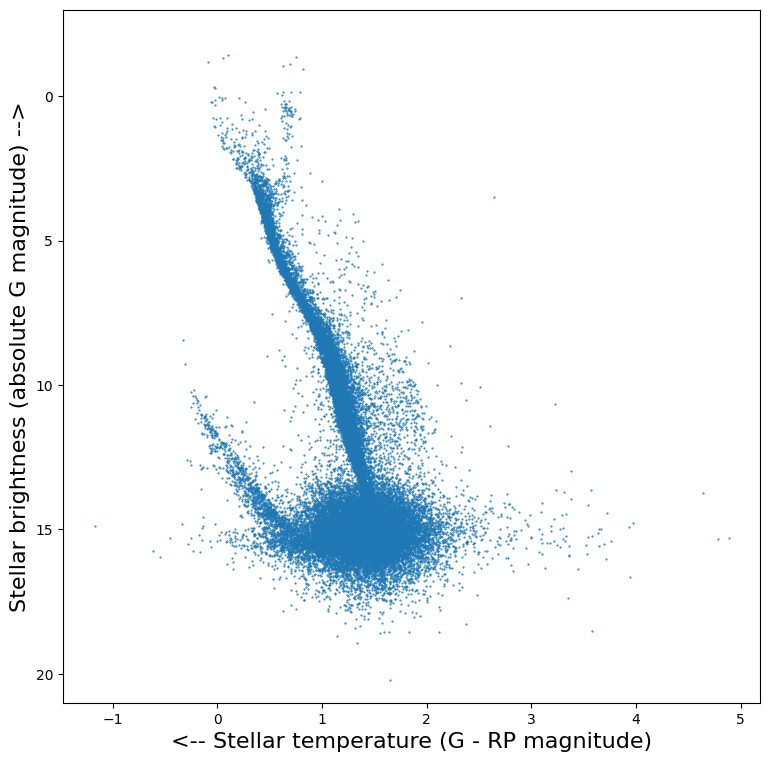

In [5]:
plt.figure(0, figsize = (9.0, 9.0))
x = list(unclassified_camd_df["g_rp"])
y = list(unclassified_camd_df["m_g"])
plt.scatter(x, y, marker = '.', s = 1)
plt.ylim(21.0, -3.0)
plt.ylabel('Stellar brightness (absolute G magnitude) -->', fontsize = 16)
plt.xlabel('<-- Stellar temperature (G - RP magnitude)', fontsize = 16)
plt.show()


<br>The problem: while we see astrophysically interesting locii in the colour / absolute-magnitude diagram in the previous cell, the lower right (cool, low temperature) regime is dominated by systematic errors (not random uncertainties - the data should be equally precise in all parts of this data space) that create contamination in the raw sample. We wish to clean the sample to obtain high reliability

* without compromising completeness;
* utilising astrometric quality features in the raw catalogue for a volume-complete sample;
* and efficiently; 

i.e. without endless iterations of manual, subjective, axis-parallel and arbitrary cuts on available catalogue attributes. A neat solution to this is to use supervised ML. In the Gaia EDR3 performance verification paper "Gaia Catalogue of Nearby Stars" (Smart, Sarro, Rybicki, et al. 2020) we use a Random Forest of decision trees on selected features having first defined a training set based on the data itself. 

An 8 mas training set of "good" examples is "cleaned" of highly probable spurious sources using <i>independent</i> photometric criteria, i.e. we require consistency of optical colours. The "bad" examples are selected having (unphysical) parallax < -8 mas, i.e. using parallax measurements that are formally highly significant, yet obviously spurious. Under the assumption of normally distributed uncertainties on the parallax measurements, this bad sample should be representative of the corresponding spurious measurements having parallax > 8 mas that contaminate the parallax-selected sample and, in particular, create the contamination illustrated in the plot above.


In [6]:
# --- Filters ---
good_df = raw_sources[
    (raw_sources['parallax'] > 8.0) &
    (np.abs(raw_sources['b']) > 25.0)
]

# Photometric consistency filter
photometric_filter = (
    ((good_df['bp_rp'] < 0.5) &
     (np.abs(good_df['phot_bp_rp_excess_factor'] - good_df['fgbp_grp_0p5']) < 2.0 * good_df['sig_cstarg'])) |
    ((good_df['bp_rp'] >= 0.5) & (good_df['bp_rp'] <= 4.0) &
     (np.abs(good_df['phot_bp_rp_excess_factor'] - good_df['fgbp_grp_0p5_4p0']) < 2.0 * good_df['sig_cstarg'])) |
    ((good_df['bp_rp'] > 4.0) &
     (np.abs(good_df['phot_bp_rp_excess_factor'] - good_df['fgbp_grp_4p0']) < 2.0 * good_df['sig_cstarg']))
)
good_df = good_df[photometric_filter]

# SMC + LMC filters
good_df = good_df[
    (good_df['dec'] < -80.0) |
    (good_df['dec'] > -65.0) |
    ((good_df['ra'] < 350.0) & (good_df['ra'] > 40.0))
]
good_df = good_df[
    (good_df['dec'] < -80.0) |
    (good_df['dec'] > -55.0) |
    (good_df['ra'] < 40.0) |
    (good_df['ra'] > 120.0)
]

# Quick filter
quick_filter_mod = 10
good_df = good_df[good_df['random_index'] % quick_filter_mod == 0]

# Label and count
good_training_df = good_df[astrometric_features]
good_training_df = good_training_df.assign(label=1)
good_training_rows = good_training_df.map_partitions(len).compute().sum()
print(f"Good training data size: {good_training_rows} rows")

# --- Bad training data
bad_df = raw_sources[raw_sources['parallax'] < -8.0]
maximal_bad_ast_count = bad_df.map_partitions(len).compute().sum()
filter_factor = max(int(maximal_bad_ast_count / good_training_rows), 1)

bad_sampled_df = bad_df.assign(mod_index=bad_df['random_index'] % filter_factor)
bad_sampled_df = bad_sampled_df[bad_sampled_df['mod_index'] == 0].drop(columns='mod_index')

bad_training_df = bad_sampled_df[astrometric_features].assign(label=0)
bad_training_rows = bad_training_df.map_partitions(len).compute().sum()
print(f"Bad  training data size: {bad_training_rows} rows")


Good training data size: 24917 rows
Bad  training data size: 25734 rows


In [7]:
# Compute Dask to Pandas
good_df = good_training_df.compute()
bad_df = bad_training_df.compute()

# Feature columns (exclude label)
feature_cols = [col for col in good_df.columns if col != 'label']

# Split into 67% train / 33% test
good_train, good_test = train_test_split(good_df, test_size=0.33, random_state=42)
bad_train, bad_test = train_test_split(bad_df, test_size=0.33, random_state=42)

# Combine good and bad for train and test
train_df = pd.concat([good_train, bad_train], ignore_index=True)
test_df = pd.concat([good_test, bad_test], ignore_index=True)

# Shuffle the combined datasets (important for many classifiers)
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
test_df = test_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Separate features and labels
X_train = train_df[feature_cols].values
y_train = train_df['label'].values

X_test = test_df[feature_cols].values
y_test = test_df['label'].values


In [8]:
# Instantiate RF classifier
rf = RandomForestClassifier(
    n_estimators=500,
    max_features='sqrt',
    criterion='gini',
    random_state=42,
    n_jobs=-1
)

# Fit the model on training data
rf.fit(X_train, y_train)

# Predict on good test set
good_test_preds = rf.predict(good_test[feature_cols].values)
good_test_probs = rf.predict_proba(good_test[feature_cols].values)  # if you want probabilities

# Predict on bad test set
bad_test_preds = rf.predict(bad_test[feature_cols].values)
bad_test_probs = rf.predict_proba(bad_test[feature_cols].values)


In [9]:
# Compute value counts for good and bad prediction results
good_pred_counts = Counter(good_test_preds)
bad_pred_counts = Counter(bad_test_preds)

# Use defaultdict to safely handle missing keys
positives = defaultdict(int, good_pred_counts)
negatives = defaultdict(int, bad_pred_counts)

# Confusion matrix (GCNS-style)
true_positives = positives[1.0]
false_positives = positives[0.0]
true_negatives = negatives[0.0]
false_negatives = negatives[1.0]

print('   |%7s%7s' % ('Pred 1', 'Pred 0'))
print('------------------------------')
print('True 1 |%7d%7d' % (true_positives, false_positives))
print('True 0 |%7d%7d' % (false_negatives, true_negatives))
print()

# Misclassification rate
num_misclassified = false_positives + false_negatives
total_num_in_test = true_positives + true_negatives + num_misclassified
misclassified_pc = 100.0 * float(num_misclassified) / float(total_num_in_test)
print('Misclassifications for the test set: %.2f %%' % misclassified_pc)


   | Pred 1 Pred 0
------------------------------
True 1 |   8178     45
True 0 |      2   8491

Misclassifications for the test set: 0.28 %


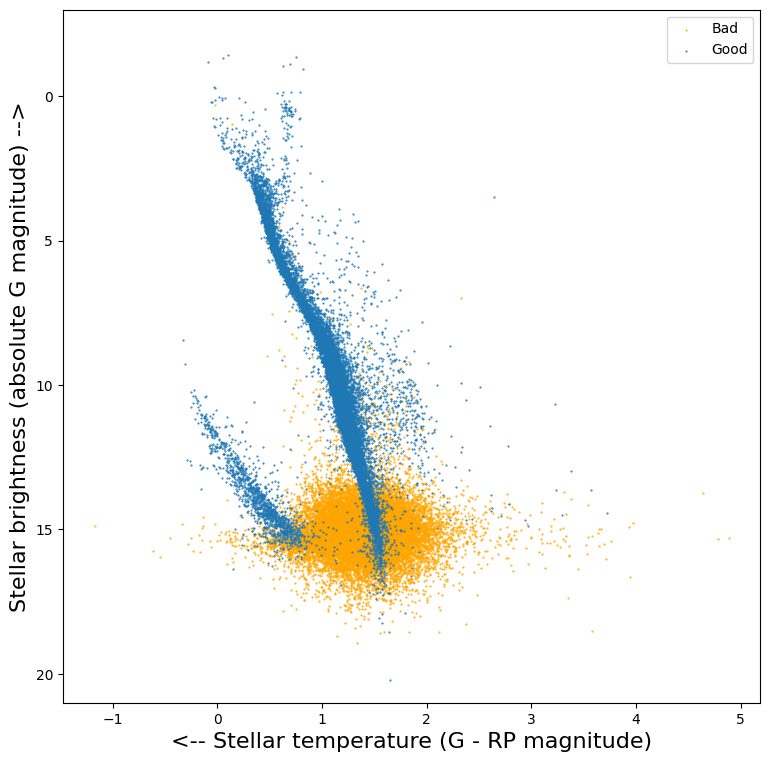

In [10]:
# Step 1: Filter unclassified sources with parallax > 8.0 and quick_plot_filter (MOD random_index == 0)
quick_plot_mod = 25  # from quick_plot_filter 'AND MOD(random_index, 25) = 0'
df_unclassified = raw_sources[
    (raw_sources['parallax'] > 8.0) &
    (raw_sources['random_index'] % quick_plot_mod == 0)
]

# Step 2: Select astrometric features and compute to NumPy for sklearn
X_to_classify = df_unclassified[astrometric_features].compute().values

# Step 3: Predict labels with trained sklearn RF model (rf)
predictions = rf.predict(X_to_classify)
probabilities = rf.predict_proba(X_to_classify)

# Step 4: Append predictions to original Pandas DataFrame
df_unclassified_pd = df_unclassified.compute()
df_unclassified_pd['prediction'] = predictions

# Step 5: Split into good and bad based on prediction
good_sources = df_unclassified_pd[df_unclassified_pd['prediction'] == 1.0].copy()
bad_sources = df_unclassified_pd[df_unclassified_pd['prediction'] == 0.0].copy()

# Step 6: Compute absolute G magnitude
good_sources['m_g'] = good_sources['phot_g_mean_mag'] + 5.0 * np.log10(good_sources['parallax'] / 100.0)
bad_sources['m_g'] = bad_sources['phot_g_mean_mag'] + 5.0 * np.log10(bad_sources['parallax'] / 100.0)

# Step 7: Plot CAMD
plt.figure(figsize=(9, 9))
plt.scatter(bad_sources['g_rp'], bad_sources['m_g'], s=1, marker='.', c='orange', label='Bad')
plt.scatter(good_sources['g_rp'], good_sources['m_g'], s=1, marker='.', label='Good')
plt.ylim(21, -3)
plt.ylabel('Stellar brightness (absolute G magnitude) -->', fontsize=16)
plt.xlabel('<-- Stellar temperature (G - RP magnitude)', fontsize=16)
plt.legend()
plt.show()


Text(0, 0.5, 'N')

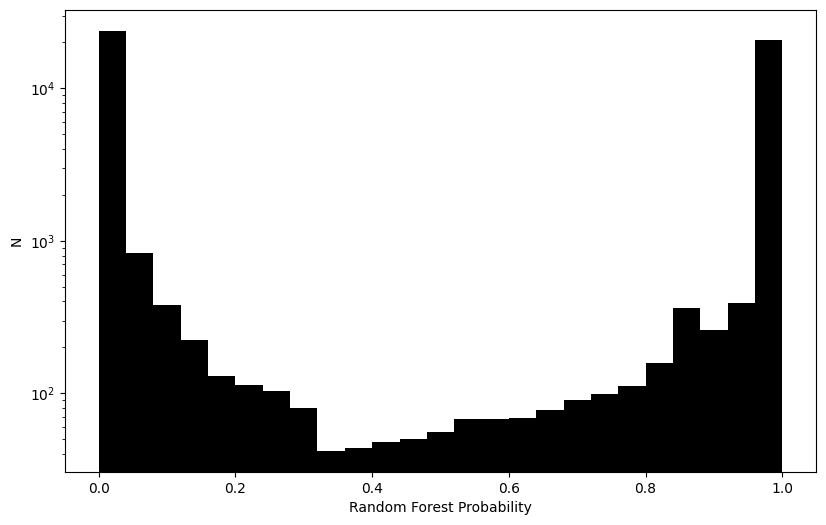

In [11]:
# histogram of the classification probabilities: cf. GCNS paper Figure 3

plt.figure(1, figsize = (9.7, 6.0))
plt.yscale('log')
x = probabilities[:,1]
plt.hist(x, bins=25, color='black')
plt.xlabel('Random Forest Probability')
plt.ylabel('N')

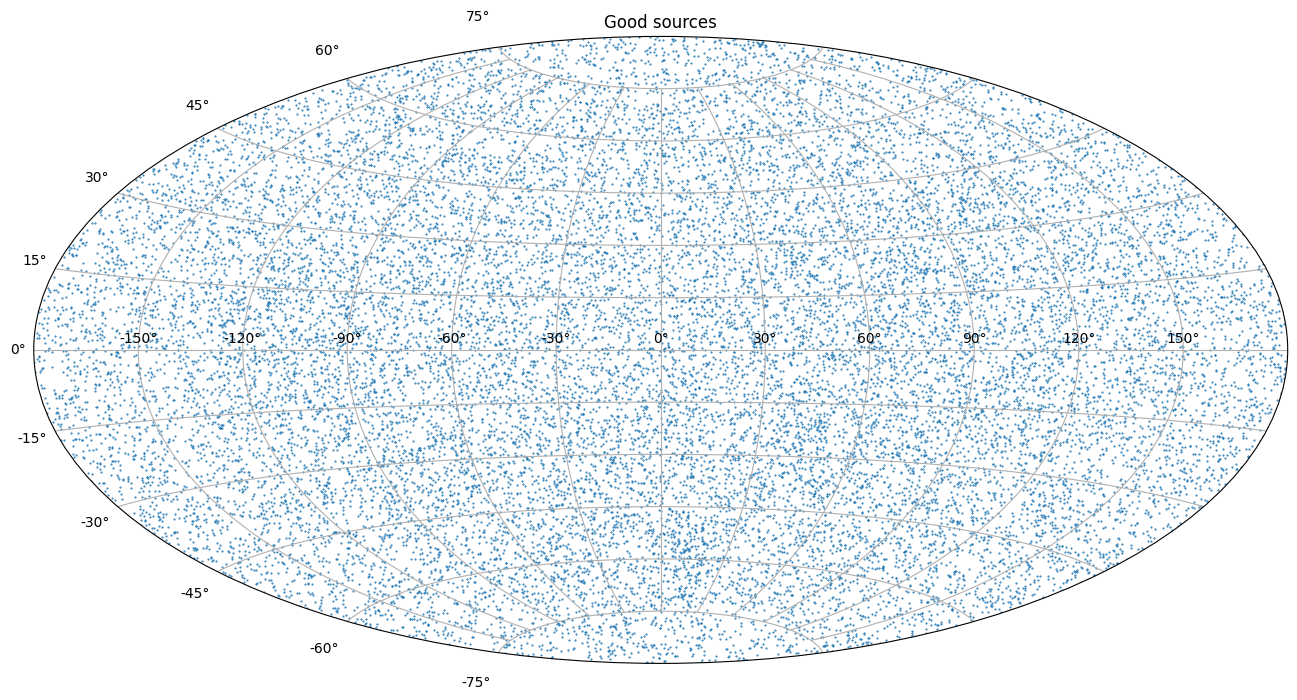

In [12]:
# cf. GCNS paper Figure 1 panels, sky distribution of good/bad sources:
plt.figure(2, figsize = (16.18, 10.0))
plt.subplot(111, projection='aitoff')
plt.grid(True)
x = list((good_sources['ra'] - 180.0) * math.pi / 180.0)
y = list(good_sources['dec'] * math.pi / 180.0)
plt.title('Good sources')
plt.scatter(x, y, marker = '.', s = 1)

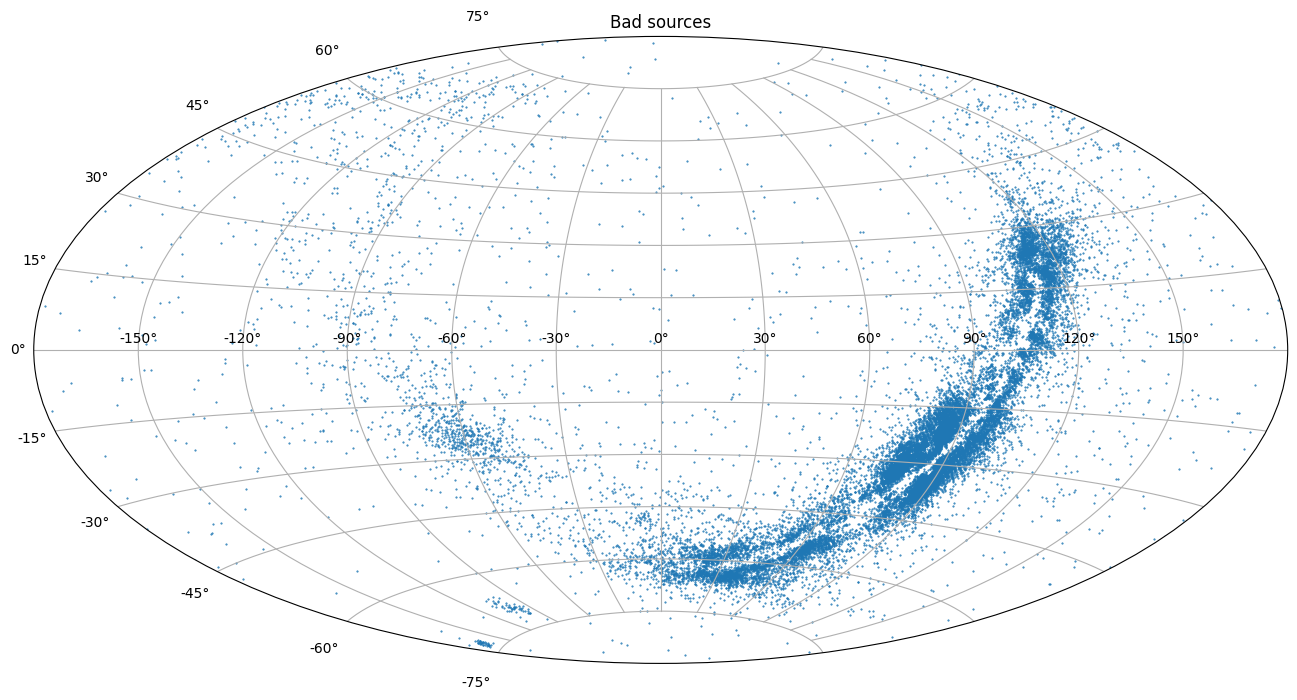

In [13]:
plt.figure(3, figsize = (16.18, 10.0))
plt.subplot(111, projection='aitoff')
plt.grid(True)
x = list((bad_sources['ra'] - 180.0) * math.pi / 180.0)
y = list(bad_sources['dec'] * math.pi / 180.0)
plt.title('Bad sources')
plt.scatter(x, y, marker = '.', s = 1)

* [Gaia Early Data Release 3: The Gaia Catalogue of Nearby Stars (R.Smart et al. 2021)](https://www.aanda.org/articles/aa/full_html/2021/05/aa39498-20/aa39498-20.html )


* [A classifier for spurious astrometric solutions in Gaia EDR3 (J.Rybizki et al. 2021)](https://arxiv.org/abs/2101.11641)
* [Python matplotlib plotting library](https://matplotlib.org)